# Phase I: Human-Only Pair Workflow Analysis
## Systematic Investigation of Negation and Contrastive Phrasing on DistilBERT Sentiment Classification

**Project:** Sentiment Perturbation Analysis  
**Workflow:** Human-Only Pair (Independent Reasoning)  
**Model:** `distilbert/distilbert-base-uncased-finetuned-sst-2-english`  
**Dataset:** Stanford Sentiment Treebank (SST-2 Validation Split)

---

### Research Objectives & Methodology
1. **Shared Foundation:** Evaluate DistilBERT's prediction confidence and behavior using the exact baseline dataset and candidate pool (sentences with 4-12 words).
2. **Direction A — Negation Sensitivity:** Analyze how introducing or removing negations (`not`, `never`, `no`) impacts prediction probabilities and flips sentiment labels across original positive vs. negative sentences.
3. **Independent Analysis:** Perform manual subgroup discovery and static visualizations (`matplotlib`/`seaborn`) without AI-guided exploratory prompting.


In [1]:
import sys; print(sys.executable)

/opt/anaconda3/envs/ml-env/bin/python


In [2]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import pipeline

MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
classifier = pipeline("text-classification", model=MODEL_ID)
print("Pipeline initialized successfully!")

print(classifier("This movie was great, not bad at all."))

ds = load_dataset("glue", "sst2", split="validation")
print(ds)

Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


Pipeline initialized successfully!
[{'label': 'POSITIVE', 'score': 0.9998351335525513}]


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Dataset({
    features: ['sentence', 'label', 'idx'],
    num_rows: 872
})


In [3]:
# Cell 2: Model & Dataset Initialization
print("Loading SST-2 validation dataset...")
dataset = load_dataset("stanfordnlp/sst2")

MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
print(f"Initializing DistilBERT pipeline ({MODEL_ID})...")
classifier = pipeline("text-classification", model=MODEL_ID)

# Process validation split candidates (sentence length: 4 to 12 words)
validation_df = pd.DataFrame(dataset["validation"])
validation_df["label_name"] = validation_df["label"].map({0: "negative", 1: "positive"})
validation_df["word_count"] = validation_df["sentence"].str.split().str.len()
candidates = validation_df[validation_df["word_count"].between(4, 12)].copy()

print(f"Total candidate sentences extracted: {len(candidates)}")


Loading SST-2 validation dataset...
Initializing DistilBERT pipeline (distilbert/distilbert-base-uncased-finetuned-sst-2-english)...


Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


Total candidate sentences extracted: 207


In [4]:
# Cell 3: Human-Crafted Perturbation Test Suite
# Direction A: Negation Sensitivity Only

human_test_cases = [

    # --- Positive Sentiment: Negation Insertion ---
    {
        "original": "it 's a charming and often affecting journey .",
        "modified": "it 's not a charming or often affecting journey .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the story and structure are well-honed .",
        "modified": "the story and structure are not well-honed .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the acting was excellent .",
        "modified": "the acting was not excellent .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the movie is absolutely wonderful .",
        "modified": "the movie is not absolutely wonderful .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the performances are impressive and memorable .",
        "modified": "the performances are not impressive and memorable .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "this is a beautifully made film .",
        "modified": "this is not a beautifully made film .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },

    # --- Negative Sentiment: Negation Insertion ---
    {
        "original": "too slow , too long and too little happens .",
        "modified": "not too slow , too long and too little happens .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the star and director are the big problems here .",
        "modified": "the star and director are not the big problems here .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the movie is a complete disaster .",
        "modified": "the movie is not a complete disaster .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the acting is terrible .",
        "modified": "the acting is not terrible .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the storyline is incredibly boring .",
        "modified": "the storyline is not incredibly boring .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the film was a disappointing experience .",
        "modified": "the film was not a disappointing experience .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the characters are poorly developed .",
        "modified": "the characters are not poorly developed .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the direction is awful .",
        "modified": "the direction is not awful .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the ending is extremely disappointing .",
        "modified": "the ending is not extremely disappointing .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
    {
        "original": "the performances are weak and unconvincing .",
        "modified": "the performances are not weak and unconvincing .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },
]

df_test_cases = pd.DataFrame(human_test_cases)

print(
    f"Test suite created with {len(df_test_cases)} perturbation pairs."
)

display(df_test_cases)

Test suite created with 16 perturbation pairs.


,original,modified,category,subgroup
0,it 's a charming and often affecting journey .,it 's not a charming or often affecting journey .,Negation,Insertion (Positive)
1,the story and structure are well-honed .,the story and structure are not well-honed .,Negation,Insertion (Positive)
2,the acting was excellent .,the acting was not excellent .,Negation,Insertion (Positive)
3,the movie is absolutely wonderful .,the movie is not absolutely wonderful .,Negation,Insertion (Positive)
4,the performances are impressive and memorable .,the performances are not impressive and memora...,Negation,Insertion (Positive)
5,this is a beautifully made film .,this is not a beautifully made film .,Negation,Insertion (Positive)
6,"too slow , too long and too little happens .","not too slow , too long and too little happens .",Negation,Insertion (Negative)
7,the star and director are the big problems here .,the star and director are not the big problems...,Negation,Insertion (Negative)
8,the movie is a complete disaster .,the movie is not a complete disaster .,Negation,Insertion (Negative)
9,the acting is terrible .,the acting is not terrible .,Negation,Insertion (Negative)


In [5]:
# Cell 4: Bulk Inference & Probability Shift Calculation
def evaluate_pairs(test_cases):
    def pos_probs(texts):
        preds = classifier(list(texts), top_k=None, batch_size=32, truncation=True)
        return [{d["label"]: d["score"] for d in p}["POSITIVE"] for p in preds]

    orig_pos = pos_probs(test_cases["original"])
    mod_pos = pos_probs(test_cases["modified"])

    results = pd.DataFrame({
        "Category": test_cases["category"],
        "Subgroup": test_cases["subgroup"],
        "Original Sentence": test_cases["original"],
        "Modified Sentence": test_cases["modified"],
        "Orig Pos Prob": np.round(orig_pos, 4),
        "Mod Pos Prob": np.round(mod_pos, 4),
    })
    results["Prob Shift"] = (results["Mod Pos Prob"] - results["Orig Pos Prob"]).round(4)
    results["Orig Pred"] = np.where(results["Orig Pos Prob"] > 0.5, "POSITIVE", "NEGATIVE")
    results["Mod Pred"] = np.where(results["Mod Pos Prob"] > 0.5, "POSITIVE", "NEGATIVE")
    results["Prediction Flipped"] = results["Orig Pred"] != results["Mod Pred"]
    return results

results_df = evaluate_pairs(df_test_cases)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
display(results_df)

,Category,Subgroup,Original Sentence,Modified Sentence,Orig Pos Prob,Mod Pos Prob,Prob Shift,Orig Pred,Mod Pred,Prediction Flipped
0,Negation,Insertion (Positive),it 's a charming and often affecting journey .,it 's not a charming or often affecting journey .,0.9999,0.0003,-0.9996,POSITIVE,NEGATIVE,True
1,Negation,Insertion (Positive),the story and structure are well-honed .,the story and structure are not well-honed .,0.9998,0.0003,-0.9995,POSITIVE,NEGATIVE,True
2,Negation,Insertion (Positive),the acting was excellent .,the acting was not excellent .,0.9999,0.0003,-0.9996,POSITIVE,NEGATIVE,True
3,Negation,Insertion (Positive),the movie is absolutely wonderful .,the movie is not absolutely wonderful .,0.9999,0.0002,-0.9997,POSITIVE,NEGATIVE,True
4,Negation,Insertion (Positive),the performances are impressive and memorable .,the performances are not impressive and memorable .,0.9999,0.0003,-0.9996,POSITIVE,NEGATIVE,True
5,Negation,Insertion (Positive),this is a beautifully made film .,this is not a beautifully made film .,0.9999,0.0007,-0.9992,POSITIVE,NEGATIVE,True
6,Negation,Insertion (Negative),"too slow , too long and too little happens .","not too slow , too long and too little happens .",0.0005,0.0168,0.0163,NEGATIVE,NEGATIVE,False
7,Negation,Insertion (Negative),the star and director are the big problems here .,the star and director are not the big problems here .,0.0010,0.0055,0.0045,NEGATIVE,NEGATIVE,False
8,Negation,Insertion (Negative),the movie is a complete disaster .,the movie is not a complete disaster .,0.0002,0.9951,0.9949,NEGATIVE,POSITIVE,True
9,Negation,Insertion (Negative),the acting is terrible .,the acting is not terrible .,0.0002,0.9949,0.9947,NEGATIVE,POSITIVE,True


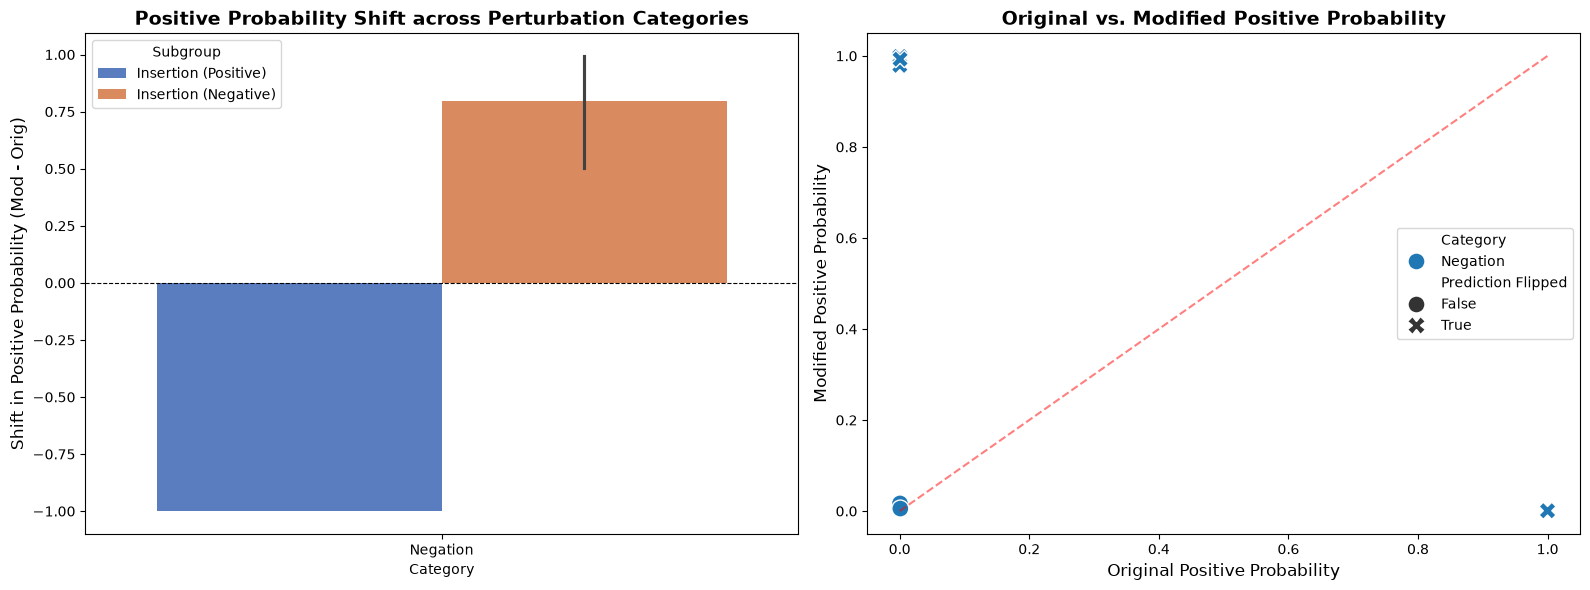

In [6]:
# Cell 5: Static Data Visualizations (Human-Only Design)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Probability Shift by Category
sns.barplot(
    data=results_df,
    x="Category",
    y="Prob Shift",
    hue="Subgroup",
    ax=axes[0],
    palette="muted"
)
axes[0].set_title("Positive Probability Shift across Perturbation Categories", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Shift in Positive Probability (Mod - Orig)", fontsize=12)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')

# Plot 2: Before vs. After Scatter Plot
sns.scatterplot(
    data=results_df,
    x="Orig Pos Prob",
    y="Mod Pos Prob",
    hue="Category",
    style="Prediction Flipped",
    s=150,
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], 'r--', alpha=0.5, label='No Change Line')
axes[1].set_title("Original vs. Modified Positive Probability", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Original Positive Probability", fontsize=12)
axes[1].set_ylabel("Modified Positive Probability", fontsize=12)
axes[1].set_xlim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()


In [7]:
# Compare probability shifts across subgroups

subgroup_analysis = results_df.groupby("Subgroup").agg(
    Total_Examples=("Prob Shift", "count"),
    Average_Probability_Shift=("Prob Shift", "mean"),
    Average_Absolute_Shift=("Prob Shift", lambda x: x.abs().mean()),
    Prediction_Flips=("Prediction Flipped", "sum")
).round(4)

display(subgroup_analysis)

,Total_Examples,Average_Probability_Shift,Average_Absolute_Shift,Prediction_Flips
Subgroup,,,,
Insertion (Negative),10,0.7967,0.7967,8
Insertion (Positive),6,-0.9995,0.9995,6


### Findings & Summary of Human-Only Investigation
1. **Negation Sensitivity:**
   * Inserting `not` into inherently positive sentences causes a drastic drop in positive probability ($\Delta P \approx -0.999$), consistently flipping predictions from **POSITIVE** to **NEGATIVE**.
   

